# Module 7: CounterShield Evaluation

## 7.1 · CounterShield evaluation configuration

In [ ]:
PROJECT_DIR = "CounterShield"
SEED = 42
CANDIDATES = ["classical", "mlp", "ensemble"]
OPERATING_POINTS = {"max_f1": None, "fpr_1pct": 0.01, "fpr_0.1pct": 0.001}
PRIMARY_OP = "max_f1"
N_BOOT = 500
ROBUSTNESS = {"n_rows": 100_000,
              "noise_sigma": [0.05, 0.1, 0.25, 0.5],
              "feature_dropout": [0.1, 0.25, 0.5],
              "threshold_shift": [-0.1, -0.05, 0.05, 0.1]}

from google.colab import drive
drive.mount("/content/drive")
import sys, warnings, platform, datetime as dt
warnings.filterwarnings("ignore", category=UserWarning)
try:
    from IPython.display import display
except ImportError:
    display = print
import matplotlib.pyplot as plt
import joblib, sklearn, torch, torch.nn as nn

import os, gc, json, time, re, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

DATASETS = ["bot_iot", "cic_ids2017", "unsw_nb15"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e8e7e2"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
MODEL_COLOR = {"classical": SERIES[0], "mlp": SERIES[1], "ensemble": SERIES[2]}

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def _strat(y):
    y = pd.Series(y).astype(str); vc = y.value_counts()
    return y.where(~y.isin(vc.index[vc < 4]), "__rare__").to_numpy()

def load_split(base, m3, key, split, cap=None, seed=42, with_features=True):
    info = m3["datasets"][key]; feats = info["feature_names"]
    cols = (feats if with_features else []) + ["y_binary", "y_class", "row"]
    d = pd.read_parquet(base / info["files"][split]["path"], columns=cols)
    if cap and len(d) > cap:
        keep, _ = train_test_split(np.arange(len(d)), train_size=cap, stratify=_strat(d["y_class"]), random_state=seed)
        d = d.iloc[np.sort(keep)].reset_index(drop=True)
    X = d[feats].to_numpy(dtype=np.float32) if with_features else None
    return X, d["y_binary"].to_numpy().astype(int), d["y_class"].astype(str).to_numpy(), d["row"].to_numpy()

def label_family(c):
    if c == "benign": return "benign"
    if "ddos" in c: return "ddos"
    if "dos" in c: return "dos"
    if any(k in c for k in ("portscan", "reconnaissance", "recon", "scan", "fingerprint", "analysis")): return "recon"
    if any(k in c for k in ("patator", "brute", "password")) and "web" not in c: return "brute_force"
    if any(k in c for k in ("web_attack", "xss", "sql")): return "web_attack"
    if c in ("bot", "botnet"): return "botnet"
    if any(k in c for k in ("theft", "exfiltration", "keylog")): return "exfiltration_theft"
    if any(k in c for k in ("backdoor", "worm")): return "malware_backdoor"
    if any(k in c for k in ("exploit", "shellcode", "infiltration", "heartbleed")): return "exploit"
    return "other"

def binary_metrics(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"threshold": float(thr), "accuracy": accuracy_score(y, pred), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "precision_attack": precision_score(y, pred, zero_division=0), "recall_attack": recall_score(y, pred, zero_division=0),
            "f1_attack": f1_score(y, pred, zero_division=0), "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
            "mcc": matthews_corrcoef(y, pred), "roc_auc": roc_auc_score(y, prob) if both else np.nan,
            "pr_auc": average_precision_score(y, prob) if both else np.nan,
            "fpr": fp / max(fp + tn, 1), "fnr": fn / max(fn + tp, 1), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def _counts_metrics(y, p):
    tp = (y & p).sum(-1); fp = (~y & p).sum(-1); fn = (y & ~p).sum(-1); tn = (~y & ~p).sum(-1)
    prec = tp / np.maximum(tp + fp, 1); rec = tp / np.maximum(tp + fn, 1)
    f1a = 2 * tp / np.maximum(2 * tp + fp + fn, 1); f1b = 2 * tn / np.maximum(2 * tn + fn + fp, 1)
    return {"precision_attack": prec, "recall_attack": rec, "f1_attack": f1a, "f1_macro": (f1a + f1b) / 2,
            "fpr": fp / np.maximum(fp + tn, 1), "fnr": fn / np.maximum(fn + tp, 1)}

def bootstrap_ci(y, pred, n_boot=500, seed=42, chunk=20):
    rng = np.random.default_rng(seed)
    y, pred = y.astype(bool), pred.astype(bool)
    n, acc = len(y), {}
    for s in range(0, n_boot, chunk):
        idx = rng.integers(0, n, size=(min(chunk, n_boot - s), n))
        for k, v in _counts_metrics(y[idx], pred[idx]).items():
            acc.setdefault(k, []).append(v)
    return {k: (float(np.percentile(np.concatenate(v), 2.5)), float(np.percentile(np.concatenate(v), 97.5))) for k, v in acc.items()}

def tune_threshold(y, prob, metric="f1_macro"):
    grid = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), np.quantile(prob, np.linspace(0.01, 0.99, 99))]))
    yb = y.astype(bool)
    P = prob[None, :] >= grid[:, None]
    scores = _counts_metrics(np.broadcast_to(yb, P.shape), P)[metric] if metric in ("f1_macro", "f1_attack") else None
    i = int(np.lexsort((np.abs(grid - 0.5), -scores))[0])
    return float(grid[i]), float(scores[i])

def threshold_for_fpr(y, prob, target):
    pb = np.sort(prob[y == 0])
    if len(pb) == 0: return 0.5
    k = int(np.floor(target * len(pb)))
    t = pb[len(pb) - k - 1] if k < len(pb) else pb[0]
    return float(np.nextafter(t, np.inf))

def per_class_detection(y_class, y, prob, thr):
    pred = (prob >= thr).astype(int)
    g = pd.DataFrame({"y_class": y_class, "y": y, "pred": pred}).groupby("y_class") \
          .agg(rows=("y", "size"), is_attack=("y", "max"), flagged=("pred", "mean")).reset_index()
    g["detection_rate"] = np.where(g.is_attack == 1, g.flagged, np.nan)
    g["false_alarm_rate"] = np.where(g.is_attack == 0, g.flagged, np.nan)
    return g.drop(columns="flagged")

def style_axes(ax):
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
    for s in ax.spines.values(): s.set_visible(False)

def load_predictions(base):
    m4 = json.loads((base / "results/module4/model_selection.json").read_text())
    m5 = json.loads((base / "results/module5/experiment_selection.json").read_text())
    P, THR, NAMES = {}, {}, {}
    for k in DATASETS:
        a = pd.read_parquet(base / "results/module4/test_predictions" / f"{k}.parquet")
        b = pd.read_parquet(base / "results/module5/test_predictions" / f"{k}.parquet")
        assert (a.row.values == b.row.values).all(), f"{k}: Module 4 and Module 5 test rows differ"
        P[k] = pd.DataFrame({"row": a.row.values, "y_binary": a.y_binary.values.astype(int), "y_class": a.y_class.astype(str).values,
                             "p_classical": a.prob_attack.values.astype(np.float32), "p_mlp": b.prob_attack.values.astype(np.float32)})
        P[k]["y_family"] = P[k].y_class.map(label_family)
        THR[k] = {"classical": m4[k]["tuned_threshold"], "mlp": m5[k]["tuned_threshold"]}
        NAMES[k] = {"classical": m4[k]["model"], "mlp": "torch_" + m5[k]["experiment"]}
    return P, THR, NAMES, m4, m5

class MLP(nn.Module):
    def __init__(self, n_in, hidden, dropout=0.1, batchnorm=False):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers += [nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def load_mlp(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = MLP(ck["n_features"], ck["exp"]["hidden"], ck["exp"]["dropout"], ck["exp"]["batchnorm"]).to(DEVICE)
    m.load_state_dict(ck["state_dict"]); m.eval(); return m

@torch.no_grad()
def mlp_proba(model, X, batch=65536):
    return np.concatenate([torch.sigmoid(model(torch.from_numpy(X[i:i + batch]).to(DEVICE))).float().cpu().numpy()
                           for i in range(0, len(X), batch)]).astype(np.float32)

def classical_proba(model, X, chunk=200_000):
    return np.concatenate([model.predict_proba(X[i:i + chunk])[:, 1] for i in range(0, len(X), chunk)]).astype(np.float32)

BASE = Path("/content/drive/MyDrive") / PROJECT_DIR
RES  = BASE / "results" / "module7"
(RES / "figures").mkdir(parents=True, exist_ok=True)
M3 = json.loads((BASE / "results/module3/module3_manifest.json").read_text())
M4 = json.loads((BASE / "results/module4/module4_manifest.json").read_text())
M5 = json.loads((BASE / "results/module5/module5_manifest.json").read_text())
PRED, THR5, MODEL_NAME, M4SEL, M5SEL = load_predictions(BASE)

VAL = {}
for k in DATASETS:
    _, yv, cv, _ = load_split(BASE, M3, k, "val", with_features=False)
    pc = np.load(BASE / "results/module4/val_probs" / f"{k}__{M4SEL[k]['model']}.npy")
    pm = np.load(BASE / "results/module5/val_probs" / f"{k}__{M5SEL[k]['experiment']}__s42.npy")
    assert len(pc) == len(pm) == len(yv), f"{k}: validation probabilities do not line up"
    VAL[k] = {"y": yv, "y_class": cv, "classical": pc, "mlp": pm, "ensemble": (pc + pm) / 2}
    PRED[k]["p_ensemble"] = (PRED[k].p_classical + PRED[k].p_mlp) / 2
(RES / "evaluation_config.json").write_text(json.dumps({"candidates": CANDIDATES, "operating_points": OPERATING_POINTS, "primary": PRIMARY_OP,
    "n_boot": N_BOOT, "robustness": ROBUSTNESS, "seed": SEED, "device": str(DEVICE),
    "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")}, indent=2))
print("device:", DEVICE, "| config ->", (RES / "evaluation_config.json").relative_to(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | config -> results/module7/evaluation_config.json


### Detector selection and operating points (validation only)

In [ ]:
SEL, OPS, cand_rows = {}, {}, []
for k in DATASETS:
    v = VAL[k]
    for c in CANDIDATES:
        thr, f1v = tune_threshold(v["y"], v[c])
        cand_rows.append({"dataset": k, "candidate": c, "val_f1_macro_tuned": f1v, "val_threshold": thr,
                          "val_pr_auc": average_precision_score(v["y"], v[c])})
    t = pd.DataFrame([r for r in cand_rows if r["dataset"] == k]).sort_values(["val_f1_macro_tuned", "val_pr_auc"], ascending=False)
    SEL[k] = t.iloc[0].candidate
    OPS[k] = {}
    for op, target in OPERATING_POINTS.items():
        OPS[k][op] = tune_threshold(v["y"], v[SEL[k]])[0] if target is None else threshold_for_fpr(v["y"], v[SEL[k]], target)
    print(f"{k:<12} CounterShield = {SEL[k]:<10} (val macro-F1 {t.iloc[0].val_f1_macro_tuned:.4f}) | thresholds " +
          ", ".join(f"{op} {th:.4f}" for op, th in OPS[k].items()) + f" | val benign rows {int((v['y'] == 0).sum()):,}")
cands = pd.DataFrame(cand_rows); cands.to_csv(RES / "candidate_selection.csv", index=False)
display(cands.pivot(index="candidate", columns="dataset", values="val_f1_macro_tuned").round(4))
(RES / "countershield_selection.json").write_text(json.dumps({k: {"detector": SEL[k], "thresholds": OPS[k]} for k in DATASETS}, indent=2))

bot_iot      CounterShield = classical  (val macro-F1 0.9978) | thresholds max_f1 0.6600, fpr_1pct 0.4933, fpr_0.1pct 0.9600 | val benign rows 1,371
cic_ids2017  CounterShield = classical  (val macro-F1 0.9980) | thresholds max_f1 0.7900, fpr_1pct 0.0045, fpr_0.1pct 0.4970 | val benign rows 279,362
unsw_nb15    CounterShield = classical  (val macro-F1 0.9350) | thresholds max_f1 0.4800, fpr_1pct 0.9094, fpr_0.1pct 0.9991 | val benign rows 7,750


dataset,bot_iot,cic_ids2017,unsw_nb15
candidate,,,
classical,0.9978,0.9980,0.9350
ensemble,0.9961,0.9977,0.9340
mlp,0.9860,0.9964,0.9182


545

## 7.2 · Detection-performance analysis

In [ ]:
det = []
for k in DATASETS:
    d = PRED[k]; y = d.y_binary.values
    for op, thr in OPS[k].items():
        p = d[f"p_{SEL[k]}"].values; r = binary_metrics(y, p, thr); ci = bootstrap_ci(y, p >= thr, N_BOOT, SEED)
        r.update(dataset=k, detector=SEL[k], operating_point=op, f1_macro_lo=ci["f1_macro"][0], f1_macro_hi=ci["f1_macro"][1],
                 recall_lo=ci["recall_attack"][0], recall_hi=ci["recall_attack"][1], fpr_lo=ci["fpr"][0], fpr_hi=ci["fpr"][1],
                 alerts_per_100k_benign=100_000 * r["fpr"], missed_per_100k_attacks=100_000 * r["fnr"])
        det.append(r)
det = pd.DataFrame(det); det.to_csv(RES / "detection_performance.csv", index=False)
cols = ["dataset", "detector", "operating_point", "threshold", "f1_macro", "f1_macro_lo", "f1_macro_hi", "precision_attack", "recall_attack",
        "mcc", "roc_auc", "pr_auc", "fpr", "fnr"]
display(det[cols].style.format({c: "{:.4f}" for c in cols[3:]}).hide(axis="index"))

allc = []
for k in DATASETS:
    thr_c = {c: cands[(cands.dataset == k) & (cands.candidate == c)].val_threshold.iloc[0] for c in CANDIDATES}
    for c in CANDIDATES:
        r = binary_metrics(PRED[k].y_binary.values, PRED[k][f"p_{c}"].values, thr_c[c]); r.update(dataset=k, candidate=c, selected=c == SEL[k]); allc.append(r)
allc = pd.DataFrame(allc); allc.to_csv(RES / "all_candidates_test.csv", index=False)
print("All candidates on test (each at its validation max-F1 threshold); selected = chosen on validation:")
display(allc[["dataset", "candidate", "selected", "threshold", "f1_macro", "pr_auc", "fpr", "fnr"]].round(4))

pcs = []
for k in DATASETS:
    for op, thr in OPS[k].items():
        pc = per_class_detection(PRED[k].y_class.values, PRED[k].y_binary.values, PRED[k][f"p_{SEL[k]}"].values, thr)
        pc.insert(0, "operating_point", op); pc.insert(0, "dataset", k); pcs.append(pc)
perclass = pd.concat(pcs, ignore_index=True); perclass.to_csv(RES / "per_class_detection.csv", index=False)
print("Per-class detection (attacks) / false-alarm rate (benign), primary operating point:")
display(perclass[perclass.operating_point == PRIMARY_OP].round(4))

dataset,detector,operating_point,threshold,f1_macro,f1_macro_lo,f1_macro_hi,precision_attack,recall_attack,mcc,roc_auc,pr_auc,fpr,fnr
bot_iot,classical,max_f1,0.6600,0.9978,0.9964,0.9989,1.0000,0.9999,0.9956,1.0000,1.0000,0.0015,0.0001
bot_iot,classical,fpr_1pct,0.4933,0.9982,0.9970,0.9993,1.0000,1.0000,0.9963,1.0000,1.0000,0.0044,0.0000
bot_iot,classical,fpr_0.1pct,0.9600,0.9909,0.9882,0.9932,1.0000,0.9996,0.9820,1.0000,1.0000,0.0007,0.0004
cic_ids2017,classical,max_f1,0.7900,0.9985,0.9983,0.9986,0.9973,0.9974,0.9969,0.9999,0.9988,0.0005,0.0026
cic_ids2017,classical,fpr_1pct,0.0045,0.9692,0.9684,0.9700,0.9018,0.9999,0.9402,0.9999,0.9988,0.0196,0.0001
cic_ids2017,classical,fpr_0.1pct,0.4970,0.9979,0.9977,0.9981,0.9936,0.9993,0.9958,0.9999,0.9988,0.0012,0.0007
unsw_nb15,classical,max_f1,0.4800,0.8544,0.8521,0.8569,0.8089,0.9795,0.7345,0.9775,0.9831,0.2835,0.0205
unsw_nb15,classical,fpr_1pct,0.9094,0.9156,0.9138,0.9175,0.9550,0.8892,0.8339,0.9775,0.9831,0.0513,0.1108
unsw_nb15,classical,fpr_0.1pct,0.9991,0.6782,0.6750,0.6814,1.0000,0.4406,0.5113,0.9775,0.9831,0.0000,0.5594


All candidates on test (each at its validation max-F1 threshold); selected = chosen on validation:


,dataset,candidate,selected,threshold,f1_macro,pr_auc,fpr,fnr
0,bot_iot,classical,True,0.66,0.9978,1.0000,0.0015,0.0001
1,bot_iot,mlp,False,0.02,0.9880,1.0000,0.0146,0.0003
2,bot_iot,ensemble,False,0.45,0.9965,1.0000,0.0007,0.0001
3,cic_ids2017,classical,True,0.79,0.9985,0.9988,0.0005,0.0026
4,cic_ids2017,mlp,False,0.70,0.9943,0.9995,0.0023,0.0065
5,cic_ids2017,ensemble,False,0.51,0.9979,0.9999,0.0011,0.0014
6,unsw_nb15,classical,True,0.48,0.8544,0.9831,0.2835,0.0205
7,unsw_nb15,mlp,False,0.50,0.8589,0.9860,0.2793,0.0162
8,unsw_nb15,ensemble,False,0.48,0.8551,0.9862,0.2899,0.0133


Per-class detection (attacks) / false-alarm rate (benign), primary operating point:


,dataset,operating_point,y_class,rows,is_attack,detection_rate,false_alarm_rate
0,bot_iot,max_f1,benign,1371,0,NaN,0.0015
1,bot_iot,max_f1,ddos,44842,1,1.0000,NaN
2,bot_iot,max_f1,dos,44743,1,1.0000,NaN
3,bot_iot,max_f1,reconnaissance,44395,1,1.0000,NaN
4,bot_iot,max_f1,theft,238,1,0.9748,NaN
15,cic_ids2017,max_f1,benign,279362,0,NaN,0.0005
16,cic_ids2017,max_f1,bot,210,1,0.6667,NaN
17,cic_ids2017,max_f1,ddos,19202,1,0.9995,NaN
18,cic_ids2017,max_f1,dos_goldeneye,1543,1,1.0000,NaN
19,cic_ids2017,max_f1,dos_hulk,25903,1,0.9993,NaN


## 7.3 · False-positive / false-negative analysis

,dataset,detector,operating_point,threshold,fp,tn,fn,tp,fpr,fnr,alerts_per_100k_benign,missed_per_100k_attacks,precision_of_alerts
0,bot_iot,classical,max_f1,0.66000,2,1369,10,134208,0.00146,0.00007,145.87892,7.45057,0.99999
1,bot_iot,classical,fpr_1pct,0.49333,6,1365,4,134214,0.00438,0.00003,437.63676,2.98023,0.99996
2,bot_iot,classical,fpr_0.1pct,0.96000,1,1370,49,134169,0.00073,0.00037,72.93946,36.50777,0.99999
3,cic_ids2017,classical,max_f1,0.79000,135,279227,129,50299,0.00048,0.00256,48.32440,255.81026,0.99732
4,cic_ids2017,classical,fpr_1pct,0.00450,5488,273874,6,50422,0.01964,0.00012,1964.47620,11.89815,0.90184
5,cic_ids2017,classical,fpr_0.1pct,0.49705,323,279039,34,50394,0.00116,0.00067,115.62059,67.42286,0.99363
6,unsw_nb15,classical,max_f1,0.48000,10490,26510,928,44404,0.28351,0.02047,28351.35135,2047.11903,0.80890
7,unsw_nb15,classical,fpr_1pct,0.90940,1899,35101,5022,40310,0.05132,0.11078,5132.43243,11078.26701,0.95501
8,unsw_nb15,classical,fpr_0.1pct,0.99907,0,37000,25360,19972,0.00000,0.55943,0.00000,55942.82185,1.00000


Classes contributing most false negatives:


,dataset,operating_point,y_class,rows,detection_rate,missed
13,bot_iot,fpr_0.1pct,reconnaissance,44395,0.9993,33.0
14,bot_iot,fpr_0.1pct,theft,238,0.9622,9.0
12,bot_iot,fpr_0.1pct,dos,44743,0.9999,4.0
9,bot_iot,fpr_1pct,theft,238,0.9874,3.0
6,bot_iot,fpr_1pct,ddos,44842,1.0000,1.0
7,bot_iot,fpr_1pct,dos,44743,1.0000,0.0
4,bot_iot,max_f1,theft,238,0.9748,6.0
3,bot_iot,max_f1,reconnaissance,44395,1.0000,2.0
2,bot_iot,max_f1,dos,44743,1.0000,1.0
49,cic_ids2017,fpr_0.1pct,dos_hulk,25903,0.9997,9.0


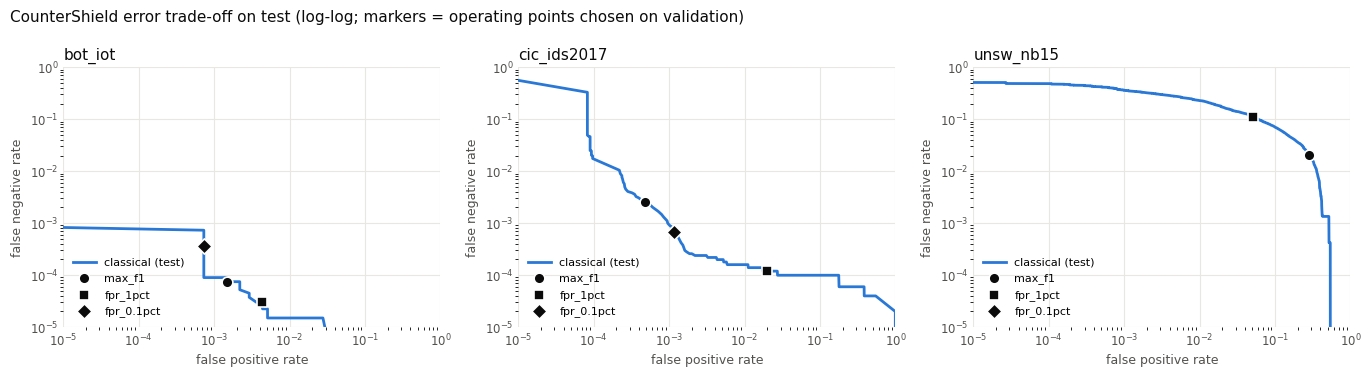

In [ ]:
fpfn = det[["dataset", "detector", "operating_point", "threshold", "fp", "tn", "fn", "tp", "fpr", "fnr", "alerts_per_100k_benign", "missed_per_100k_attacks"]].copy()
fpfn["precision_of_alerts"] = fpfn.tp / (fpfn.tp + fpfn.fp).clip(lower=1)
fpfn.to_csv(RES / "fp_fn_by_operating_point.csv", index=False)
display(fpfn.round(5))

miss = perclass[(perclass.is_attack == 1)].copy(); miss["missed"] = (1 - miss.detection_rate) * miss.rows
top_missed = miss.sort_values(["dataset", "operating_point", "missed"], ascending=[True, True, False]).groupby(["dataset", "operating_point"]).head(3)
top_missed.to_csv(RES / "top_missed_classes.csv", index=False)
print("Classes contributing most false negatives:"); display(top_missed[["dataset", "operating_point", "y_class", "rows", "detection_rate", "missed"]].round(4))

fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.6 * len(DATASETS), 3.8))
OP_MARK = {"max_f1": "o", "fpr_1pct": "s", "fpr_0.1pct": "D"}
for ax, k in zip(axes, DATASETS):
    d = PRED[k]; y = d.y_binary.values; p = d[f"p_{SEL[k]}"].values
    fpr, tpr, _ = roc_curve(y, p); keep = np.unique(np.linspace(0, len(fpr) - 1, min(len(fpr), 3000)).astype(int))
    ax.plot(np.clip(fpr[keep], 1e-6, 1), np.clip(1 - tpr[keep], 1e-6, 1), color=MODEL_COLOR[SEL[k]], linewidth=2, label=f"{SEL[k]} (test)")
    for op, thr in OPS[k].items():
        r = det[(det.dataset == k) & (det.operating_point == op)].iloc[0]
        ax.scatter(max(r.fpr, 1e-6), max(r.fnr, 1e-6), marker=OP_MARK[op], s=60, color=INK, edgecolor="white", linewidth=1.2, zorder=3, label=op)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1e-5, 1); ax.set_ylim(1e-5, 1)
    ax.set_xlabel("false positive rate", color=MUTED, fontsize=9); ax.set_ylabel("false negative rate", color=MUTED, fontsize=9)
    ax.set_title(k, loc="left", fontsize=11, color=INK); style_axes(ax); ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("CounterShield error trade-off on test (log-log; markers = operating points chosen on validation)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "fp_fn_tradeoff.png", dpi=200, bbox_inches="tight"); plt.show()

## 7.4 · Robustness analysis

bot_iot      done (100,000 rows, detector classical)
cic_ids2017  done (100,000 rows, detector classical)
unsw_nb15    done (82,332 rows, detector classical)


,dataset,perturbation,strength,f1_macro,fpr,fnr,roc_auc,f1_drop
0,bot_iot,none,0.00,0.9980,0.0010,0.0001,1.0000,0.0000
1,bot_iot,gaussian_noise,0.05,0.9927,0.0178,0.0001,0.9986,0.0053
2,bot_iot,gaussian_noise,0.10,0.9820,0.0485,0.0002,0.9983,0.0160
3,bot_iot,gaussian_noise,0.25,0.9413,0.1118,0.0012,0.9948,0.0567
4,bot_iot,gaussian_noise,0.50,0.7956,0.3225,0.0061,0.9707,0.2024
5,bot_iot,feature_dropout,0.10,0.9927,0.0208,0.0001,0.9992,0.0053
6,bot_iot,feature_dropout,0.25,0.9664,0.1128,0.0001,0.9969,0.0316
7,bot_iot,feature_dropout,0.50,0.8538,0.4313,0.0003,0.9726,0.1443
8,bot_iot,threshold_shift,-0.10,0.9980,0.0020,0.0001,1.0000,0.0000
9,bot_iot,threshold_shift,-0.05,0.9978,0.0020,0.0001,1.0000,0.0003


MLP seed stability (std of validation macro-F1 over seeds):


dataset,bot_iot,cic_ids2017,unsw_nb15
experiment,,,
mlp_128_64,0.00851,0.00009,0.00186
mlp_256_128_64,0.00439,0.00004,0.00161
mlp_512_256,0.00455,0.00016,0.00118


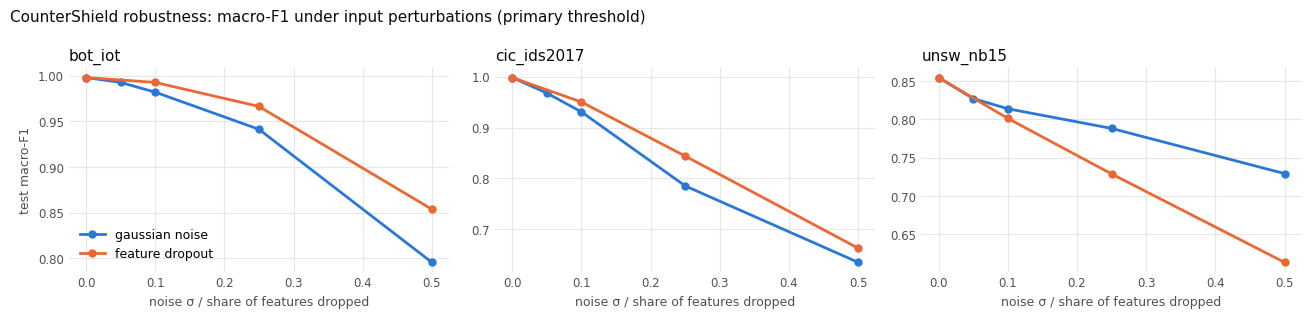

In [ ]:
rng = np.random.default_rng(SEED)
rob = []
for k in DATASETS:
    X, y, cl, rows = load_split(BASE, M3, k, "test", cap=ROBUSTNESS["n_rows"], seed=SEED)
    det_name = SEL[k]
    clf = joblib.load(BASE / M4["final_models"][k]["path"])["model"] if det_name in ("classical", "ensemble") else None
    mlp = load_mlp(BASE / M5["final_models"][k]["path"]) if det_name in ("mlp", "ensemble") else None
    def score(Xp):
        if det_name == "classical": return classical_proba(clf, Xp)
        if det_name == "mlp": return mlp_proba(mlp, Xp)
        return (classical_proba(clf, Xp) + mlp_proba(mlp, Xp)) / 2
    thr = OPS[k][PRIMARY_OP]; p0 = score(X); base_m = binary_metrics(y, p0, thr)
    rob.append({"dataset": k, "perturbation": "none", "strength": 0.0, **{m: base_m[m] for m in ["f1_macro", "fpr", "fnr", "roc_auc"]}})
    for s in ROBUSTNESS["noise_sigma"]:
        m = binary_metrics(y, score(X + rng.normal(0, s, X.shape).astype(np.float32)), thr)
        rob.append({"dataset": k, "perturbation": "gaussian_noise", "strength": s, **{kk: m[kk] for kk in ["f1_macro", "fpr", "fnr", "roc_auc"]}})
    for q in ROBUSTNESS["feature_dropout"]:
        Xd = X.copy(); Xd[rng.random(X.shape) < q] = 0.0
        m = binary_metrics(y, score(Xd), thr)
        rob.append({"dataset": k, "perturbation": "feature_dropout", "strength": q, **{kk: m[kk] for kk in ["f1_macro", "fpr", "fnr", "roc_auc"]}})
        del Xd
    for dlt in ROBUSTNESS["threshold_shift"]:
        m = binary_metrics(y, p0, float(np.clip(thr + dlt, 1e-6, 1 - 1e-6)))
        rob.append({"dataset": k, "perturbation": "threshold_shift", "strength": dlt, **{kk: m[kk] for kk in ["f1_macro", "fpr", "fnr", "roc_auc"]}})
    print(f"{k:<12} done ({len(y):,} rows, detector {det_name})")
    del X, clf, mlp; gc.collect()
rob = pd.DataFrame(rob)
rob["f1_drop"] = rob.groupby("dataset").f1_macro.transform(lambda s: s.iloc[0]) - rob.f1_macro
rob.to_csv(RES / "robustness.csv", index=False)
display(rob.round(4))
seed_std = pd.read_csv(BASE / "results/module5/validation_summary.csv")
print("MLP seed stability (std of validation macro-F1 over seeds):")
display(seed_std.pivot(index="experiment", columns="dataset", values="f1_macro_std").round(5))

fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.4 * len(DATASETS), 3.2))
for ax, k in zip(axes, DATASETS):
    t = rob[rob.dataset == k]; b = t[t.perturbation == "none"].f1_macro.iloc[0]
    for (pert, col) in [("gaussian_noise", SERIES[0]), ("feature_dropout", SERIES[1])]:
        s = t[t.perturbation == pert]
        ax.plot([0] + s.strength.tolist(), [b] + s.f1_macro.tolist(), color=col, linewidth=2, marker="o", markersize=5, label=pert.replace("_", " "))
    ax.set_title(k, loc="left", fontsize=11, color=INK); ax.set_xlabel("noise σ / share of features dropped", color=MUTED, fontsize=9); style_axes(ax)
axes[0].set_ylabel("test macro-F1", color=MUTED, fontsize=9); axes[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle("CounterShield robustness: macro-F1 under input perturbations (primary threshold)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "robustness.png", dpi=200, bbox_inches="tight"); plt.show()

## 7.5 · Cross-dataset results

In [ ]:
xd = det[det.operating_point == PRIMARY_OP][["dataset", "detector", "threshold", "f1_macro", "f1_macro_lo", "f1_macro_hi", "recall_attack", "fpr", "roc_auc", "pr_auc"]]
display(xd.round(4))
fam = []
for k in DATASETS:
    d = PRED[k]; pred = d[f"p_{SEL[k]}"].values >= OPS[k][PRIMARY_OP]
    g = pd.DataFrame({"family": d.y_family, "pred": pred}).groupby("family").pred.agg(["size", "mean"])
    for f, r in g.iterrows():
        fam.append({"dataset": k, "family": f, "rows": int(r["size"]), "rate": 1 - r["mean"] if f == "benign" else r["mean"]})
fam = pd.DataFrame(fam); fam.to_csv(RES / "family_detection_cross_dataset.csv", index=False)
print("Detection rate by attack family (benign = specificity):"); display(fam.pivot(index="family", columns="dataset", values="rate").round(4))
tr_path = BASE / "results/module6/cross_dataset_transfer.csv"
transfer = pd.read_csv(tr_path) if tr_path.exists() else pd.DataFrame()
print("Cross-dataset transfer (Module 6, shared Argus features):"); display(transfer.round(4) if len(transfer) else "run Module 6 first")

,dataset,detector,threshold,f1_macro,f1_macro_lo,f1_macro_hi,recall_attack,fpr,roc_auc,pr_auc
0,bot_iot,classical,0.66,0.9978,0.9964,0.9989,0.9999,0.0015,1.0000,1.0000
3,cic_ids2017,classical,0.79,0.9985,0.9983,0.9986,0.9974,0.0005,0.9999,0.9988
6,unsw_nb15,classical,0.48,0.8544,0.8521,0.8569,0.9795,0.2835,0.9775,0.9831


Detection rate by attack family (benign = specificity):


dataset,bot_iot,cic_ids2017,unsw_nb15
family,,,
benign,0.9985,0.9995,0.7165
botnet,NaN,0.6667,NaN
brute_force,NaN,0.9956,NaN
ddos,1.0000,0.9995,NaN
dos,1.0000,0.9991,0.9768
exfiltration_theft,0.9748,NaN,NaN
exploit,NaN,0.5714,0.9877
malware_backdoor,NaN,NaN,0.9856
other,NaN,NaN,0.9740


Cross-dataset transfer (Module 6, shared Argus features):


,train_on,test_on,setting,f1_macro,roc_auc,pr_auc,fpr,fnr,test_attack_rate
0,bot_iot,bot_iot,in-domain,0.9893,0.9996,1.0000,0.0080,0.0004,0.9899
1,bot_iot,unsw_nb15,cross-domain,0.3097,0.3458,0.4871,0.6901,0.6892,0.5506
2,unsw_nb15,bot_iot,cross-domain,0.2572,0.1489,0.9661,0.9555,0.6517,0.9899
3,unsw_nb15,unsw_nb15,in-domain,0.8467,0.9719,0.9784,0.2917,0.0271,0.5506


## 7.6 · Final CounterShield results table

In [ ]:
final = []
for k in DATASETS:
    for op in OPERATING_POINTS:
        r = det[(det.dataset == k) & (det.operating_point == op)].iloc[0]
        worst = rob[(rob.dataset == k) & rob.perturbation.isin(["gaussian_noise", "feature_dropout"]) & (rob.strength <= 0.25)].f1_drop.max()
        final.append({"Dataset": k, "Detector": {"classical": MODEL_NAME[k]["classical"], "mlp": MODEL_NAME[k]["mlp"],
                                   "ensemble": f"{MODEL_NAME[k]['classical']} + {MODEL_NAME[k]['mlp']} (mean prob.)"}[SEL[k]],
                      "Operating point": op, "Threshold": r.threshold, "Macro-F1": r.f1_macro, "Macro-F1 95% CI": f"[{r.f1_macro_lo:.4f}, {r.f1_macro_hi:.4f}]",
                      "Attack F1": r.f1_attack, "Precision": r.precision_attack, "Recall": r.recall_attack, "MCC": r.mcc,
                      "ROC-AUC": r.roc_auc, "PR-AUC": r.pr_auc, "FPR": r.fpr, "FNR": r.fnr,
                      "Alerts / 100k benign": r.alerts_per_100k_benign, "Worst F1 drop (noise/dropout ≤ 0.25)": worst if op == PRIMARY_OP else np.nan,
                      "Note": "unattainable: too many validation benign rows tied at the top score" if r.threshold > 1 else ""})
final = pd.DataFrame(final)
final.to_csv(RES / "final_countershield_results.csv", index=False)
num = [c for c in final.columns if final[c].dtype.kind == "f"]
def md_table(df):
    try:
        return df.to_markdown(index=False, floatfmt=".4f")
    except ImportError:
        cols = list(df.columns)
        fmt = lambda v: f"{v:.4f}" if isinstance(v, float) else str(v)
        return "\n".join(["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)] + ["| " + " | ".join(fmt(v) for v in r) + " |" for r in df.itertuples(index=False)])
(RES / "final_countershield_results.md").write_text(md_table(final))
try:
    (RES / "final_countershield_results.tex").write_text(final.style.format({c: "{:.4f}" for c in num}).hide(axis="index").to_latex(hrules=True))
except Exception as e:
    print("LaTeX export skipped:", e)
display(final.style.format({c: "{:.4f}" for c in num}, na_rep="").hide(axis="index"))

Dataset,Detector,Operating point,Threshold,Macro-F1,Macro-F1 95% CI,Attack F1,Precision,Recall,MCC,ROC-AUC,PR-AUC,FPR,FNR,Alerts / 100k benign,Worst F1 drop (noise/dropout ≤ 0.25),Note
bot_iot,random_forest,max_f1,0.6600,0.9978,"[0.9964, 0.9989]",1.0000,1.0000,0.9999,0.9956,1.0000,1.0000,0.0015,0.0001,145.8789,0.0567,
bot_iot,random_forest,fpr_1pct,0.4933,0.9982,"[0.9970, 0.9993]",1.0000,1.0000,1.0000,0.9963,1.0000,1.0000,0.0044,0.0000,437.6368,,
bot_iot,random_forest,fpr_0.1pct,0.9600,0.9909,"[0.9882, 0.9932]",0.9998,1.0000,0.9996,0.9820,1.0000,1.0000,0.0007,0.0004,72.9395,,
cic_ids2017,hist_gb,max_f1,0.7900,0.9985,"[0.9983, 0.9986]",0.9974,0.9973,0.9974,0.9969,0.9999,0.9988,0.0005,0.0026,48.3244,0.2133,
cic_ids2017,hist_gb,fpr_1pct,0.0045,0.9692,"[0.9684, 0.9700]",0.9483,0.9018,0.9999,0.9402,0.9999,0.9988,0.0196,0.0001,1964.4762,,
cic_ids2017,hist_gb,fpr_0.1pct,0.4970,0.9979,"[0.9977, 0.9981]",0.9965,0.9936,0.9993,0.9958,0.9999,0.9988,0.0012,0.0007,115.6206,,
unsw_nb15,hist_gb,max_f1,0.4800,0.8544,"[0.8521, 0.8569]",0.8861,0.8089,0.9795,0.7345,0.9775,0.9831,0.2835,0.0205,28351.3514,0.1257,
unsw_nb15,hist_gb,fpr_1pct,0.9094,0.9156,"[0.9138, 0.9175]",0.9209,0.9550,0.8892,0.8339,0.9775,0.9831,0.0513,0.1108,5132.4324,,
unsw_nb15,hist_gb,fpr_0.1pct,0.9991,0.6782,"[0.6750, 0.6814]",0.6117,1.0000,0.4406,0.5113,0.9775,0.9831,0.0000,0.5594,0.0000,,


## 7.7 · Reproducibility / checkpoint audit

In [ ]:
audit = []
def A(area, item, ok, detail=""):
    audit.append({"area": area, "item": item, "status": "PASS" if ok is True else ("WARN" if ok is None else "FAIL"), "detail": str(detail)})
def check_file(area, rel, sha=None):
    f = BASE / rel
    if not f.exists(): return A(area, rel, False, "missing")
    if sha is None: return A(area, rel, True, "present (no hash recorded)")
    h = sha256_file(f); A(area, rel, h == sha, "sha256 ok" if h == sha else f"sha256 mismatch ({h[:12]} vs {sha[:12]})")
prov = BASE / "processed/provenance/provenance.json"
if prov.exists():
    P1 = json.loads(prov.read_text())
    for k in DATASETS:
        if k in P1 and "processed_file" in P1[k]: check_file("module1", P1[k]["processed_file"], P1[k].get("processed_sha256"))
        A("module1", f"{k} Kaggle version recorded", P1.get(k, {}).get("kaggle_version") is not None or None, P1.get(k, {}).get("kaggle_version"))
else:
    A("module1", "processed/provenance/provenance.json", False, "missing")
m2p = BASE / "results/module2/module2_manifest.json"
if m2p.exists():
    M2 = json.loads(m2p.read_text())
    for k, v in M2["datasets"].items():
        check_file("module2", v["input"], v["input_sha256"]); check_file("module2", v["output"], v["output_sha256"])
else:
    A("module2", "module2_manifest.json", False, "missing")
for k, v in M3["datasets"].items():
    check_file("module3", v["preprocessor"], v["preprocessor_sha256"]); check_file("module3", v["split_manifest"])
    for s, fv in v["files"].items(): check_file("module3", fv["path"], fv["sha256"])
for k, v in M4["final_models"].items(): check_file("module4", v["path"], v["sha256"])
for k, v in M5["final_models"].items(): check_file("module5", v["path"], v["sha256"])
for rel in ["configs/feature_schema.json", "configs/preprocessing_config.json", "results/module4/training_config.json",
            "results/module5/mlp_config.json", "results/module6/module6_manifest.json", "results/module7/evaluation_config.json"]:
    check_file("configs", rel)
pc = json.loads((BASE / "configs/preprocessing_config.json").read_text())
A("seeds", "split seed (Module 3)", all("seed" in v for v in pc["split"].values()), {k: v["seed"] for k, v in pc["split"].items()})
A("seeds", "training seed (Module 4)", "seed" in json.loads((BASE / "results/module4/training_config.json").read_text()))
A("seeds", "MLP seeds (Module 5)", "seeds" in json.loads((BASE / "results/module5/mlp_config.json").read_text()))
for k in DATASETS:
    X, _, _, _ = load_split(BASE, M3, k, "test"); X = X[:2000]
    try:
        clf = joblib.load(BASE / M4["final_models"][k]["path"])["model"]
        ok = np.allclose(classical_proba(clf, X), PRED[k].p_classical.values[:2000], atol=1e-6); A("determinism", f"{k} classical reproduces saved predictions", ok)
    except Exception as e:
        A("determinism", f"{k} classical reproduces saved predictions", False, repr(e)[:120])
    try:
        mlp = load_mlp(BASE / M5["final_models"][k]["path"])
        diff = float(np.abs(mlp_proba(mlp, X) - PRED[k].p_mlp.values[:2000]).max())
        A("determinism", f"{k} MLP reproduces saved predictions", True if diff < 1e-4 else (None if diff < 1e-2 else False), f"max |diff| {diff:.2e}")
    except Exception as e:
        A("determinism", f"{k} MLP reproduces saved predictions", False, repr(e)[:120])
A("environment", "scikit-learn version", True if sklearn.__version__ == M3["sklearn"] else None, f"now {sklearn.__version__}; Module 3/4 {M3['sklearn']}")
A("environment", "torch version", True if torch.__version__ == M5["torch"] else None, f"now {torch.__version__}; Module 5 {M5['torch']}")
audit = pd.DataFrame(audit); audit.to_csv(RES / "reproducibility_audit.csv", index=False)
print(audit.status.value_counts().to_string()); display(audit)

status
PASS    50


,area,item,status,detail
0,module1,processed/bot_iot.parquet,PASS,sha256 ok
1,module1,bot_iot Kaggle version recorded,PASS,1
2,module1,processed/cic_ids2017.parquet,PASS,sha256 ok
3,module1,cic_ids2017 Kaggle version recorded,PASS,2
4,module1,processed/unsw_nb15.parquet,PASS,sha256 ok
5,module1,unsw_nb15 Kaggle version recorded,PASS,2
6,module2,processed/bot_iot.parquet,PASS,sha256 ok
7,module2,processed/clean/bot_iot_clean.parquet,PASS,sha256 ok
8,module2,processed/cic_ids2017.parquet,PASS,sha256 ok
9,module2,processed/clean/cic_ids2017_clean.parquet,PASS,sha256 ok


### Module 7 summary

In [ ]:
lines = ["# Module 7 — CounterShield evaluation", "",
         "CounterShield = per-dataset detector chosen on validation among classical (Module 4), MLP (Module 5) and their probability-average ensemble; "
         "operating points chosen on validation; everything below is on the held-out test split.", "",
         "## Selected detectors", ""] + [f"- **{k}**: {SEL[k]} — thresholds " + ", ".join(f"{op} {t:.4f}" for op, t in OPS[k].items()) for k in DATASETS]
lines += ["", "## Final results", "", md_table(final.drop(columns=["Detector"])), "",
          "## Robustness (primary operating point, worst macro-F1 drop)", ""]
for k in DATASETS:
    t = rob[(rob.dataset == k) & (rob.perturbation != "none")]
    lines.append(f"- {k}: " + "; ".join(f"{p} worst drop {t[t.perturbation == p].f1_drop.max():+.4f}" for p in ["gaussian_noise", "feature_dropout", "threshold_shift"]))
lines += ["", f"## Reproducibility audit: {int((audit.status == 'PASS').sum())} pass, {int((audit.status == 'WARN').sum())} warn, {int((audit.status == 'FAIL').sum())} fail"]
lines += [f"- {r['status']}: {r['area']} / {r['item']} ({r['detail']})" for _, r in audit[audit.status != "PASS"].iterrows()]
(RES / "summary.md").write_text("\n".join(lines))
(RES / "module7_manifest.json").write_text(json.dumps({"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    "module": "7 - CounterShield evaluation", "selection": {k: {"detector": SEL[k], "thresholds": OPS[k]} for k in DATASETS},
    "environment": {"python": sys.version.split()[0], "sklearn": sklearn.__version__, "torch": torch.__version__, "device": str(DEVICE)},
    "outputs": sorted(str(p.relative_to(BASE)) for p in RES.rglob("*") if p.is_file())}, indent=2, default=str))
print("\n".join(lines))

# Module 7 — CounterShield evaluation

CounterShield = per-dataset detector chosen on validation among classical (Module 4), MLP (Module 5) and their probability-average ensemble; operating points chosen on validation; everything below is on the held-out test split.

## Selected detectors

- **bot_iot**: classical — thresholds max_f1 0.6600, fpr_1pct 0.4933, fpr_0.1pct 0.9600
- **cic_ids2017**: classical — thresholds max_f1 0.7900, fpr_1pct 0.0045, fpr_0.1pct 0.4970
- **unsw_nb15**: classical — thresholds max_f1 0.4800, fpr_1pct 0.9094, fpr_0.1pct 0.9991

## Final results

| Dataset     | Operating point   |   Threshold |   Macro-F1 | Macro-F1 95% CI   |   Attack F1 |   Precision |   Recall |    MCC |   ROC-AUC |   PR-AUC |    FPR |    FNR |   Alerts / 100k benign |   Worst F1 drop (noise/dropout ≤ 0.25) | Note   |
|:------------|:------------------|------------:|-----------:|:------------------|------------:|------------:|---------:|-------:|----------:|---------:|-------:|-------:|--